# 04c · Le RF et l'autoencodeur dépendent-ils des fenêtres ?

**Date :** 5 novembre 2026

**Pourquoi :** le notebook 04b a montré que la détection web du MLP disparaît sans les 4 colonnes de fenêtre, et que 100 % des attaques de train ont le profil « 1 machine, 1 port par minute ». Le RF et l'autoencodeur, retenus pour le pipeline, utilisent aussi ces colonnes. Leurs bons chiffres sur portscan et DDoS reposent-ils sur la même propriété du scénario ?

**Ce qui est fait :** RF (profondeur 20, sans poids de classe) et autoencodeur (goulot 8), entraînés avec et sans `w_conn`, `w_dst_ports`, `w_dst_hosts`, `w_rst_rate`, sur 5 graines.

**Fixé avant les calculs :**
- Mêmes réglages que les modèles retenus. Seuil de l'autoencodeur : 99e percentile du benign de val, pour chaque entraînement.
- test_inconnu sert seulement à mesurer. test_connu n'est pas utilisé. **Aucun modèle du pipeline ne change ici.**
- Lecture graine par graine : on compare les plus petites et les plus grandes valeurs avec et sans fenêtres.
- Une baisse montre que le modèle dépend de ces colonnes, pas qu'il triche : pour un portscan, contacter des centaines de ports en une minute est un vrai comportement d'attaque.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(Path.cwd().parent / "src"))
from isocrates.ml.data import LABEL, BENIGN, ROOT
from isocrates.ml.supervised import (load_sets, load_model, save_model, signed_log, fit_rf, macro_f1_without,
                                     detection_by_class, MODELS)
from isocrates.ml.anomaly import (fit_autoencoder, reconstruction_error, threshold_from_benign,
                                  detection_table, mean_attack_recall)
from isocrates.ml.verification import kept_positions

REPORTS = ROOT / "reports"
sns.set_theme(style="whitegrid")

# test_connu n'est pas chargé
sets, features = load_sets(("train", "val", "test_inconnu"))
X_train = sets["train"][features].to_numpy(np.float32)
X_val = sets["val"][features].to_numpy(np.float32)
X_inconnu = sets["test_inconnu"][features].to_numpy(np.float32)
y_train = sets["train"][LABEL].to_numpy()
y_val = sets["val"][LABEL].to_numpy()
y_inconnu = sets["test_inconnu"][LABEL].to_numpy()
del sets

WINDOW_COLUMNS = ["w_conn", "w_dst_ports", "w_dst_hosts", "w_rst_rate"]
kept = kept_positions(features, WINDOW_COLUMNS)
known = sorted(set(y_train))
SEEDS = [0, 1, 2, 3, 4]
print(len(features), "colonnes avec fenêtres,", len(kept), "sans")

# Résultats enregistrés après chaque entraînement, pour pouvoir reprendre
RESULTS_FILE = MODELS / "04c_resultats.joblib"
if RESULTS_FILE.exists():
    results = load_model("04c_resultats")
else:
    results = {}

78 colonnes avec fenêtres, 74 sans


## 1. Random Forest

In [2]:
for version, columns in [("avec fenêtres", list(range(len(features)))), ("sans fenêtres", kept)]:
    for seed in SEEDS:
        key = ("rf", version, seed)
        if key in results:
            continue
        model, duration = fit_rf(X_train[:, columns], y_train, max_depth=20, seed=seed)
        val_predictions = model.predict(X_val[:, columns])
        row = {"modèle": "RF", "version": version, "graine": seed,
               "macro-F1 val sans heartbleed": macro_f1_without(y_val, val_predictions, known, "heartbleed")}
        row.update(detection_by_class(y_inconnu, model.predict(X_inconnu[:, columns])).to_dict())
        results[key] = row
        save_model(results, "04c_resultats")

rf_rows = []
for key, row in results.items():
    if key[0] == "rf":
        rf_rows.append(row)
rf_runs = pd.DataFrame(rf_rows)
rf_runs.round(4)

,modèle,version,graine,macro-F1 val sans heartbleed,benign,bot,ddos,portscan,webattack_bruteforce,webattack_sql_injection,webattack_xss
0,RF,avec fenêtres,0,0.9722,0.0,0.0,0.9773,0.0003,0.1088,0.0833,0.1135
1,RF,avec fenêtres,1,0.9722,0.0,0.0,0.9883,0.0003,0.1096,0.1667,0.1135
2,RF,avec fenêtres,2,0.9699,0.0,0.0,0.9703,0.0003,0.1096,0.0000,0.1120
3,RF,avec fenêtres,3,0.9727,0.0,0.0,0.9683,0.0003,0.1015,0.1667,0.1074
4,RF,avec fenêtres,4,0.9724,0.0,0.0,0.9599,0.0004,0.1066,0.1667,0.1120
5,RF,sans fenêtres,0,0.9552,0.0,0.0,0.0217,0.0007,0.0051,0.0833,0.0000
6,RF,sans fenêtres,1,0.9658,0.0,0.0,0.2964,0.0007,0.0176,0.0833,0.0045
7,RF,sans fenêtres,2,0.9639,0.0,0.0,0.4350,0.0007,0.0176,0.0833,0.0045
8,RF,sans fenêtres,3,0.9654,0.0,0.0,0.0412,0.0007,0.0074,0.0833,0.0015
9,RF,sans fenêtres,4,0.9652,0.0,0.0,0.0385,0.0007,0.0169,0.0833,0.0030


## 2. Autoencodeur

Même préparation que dans le notebook 04 : log signé et standardisation ajustés sur le benign de train.

In [3]:
X_train_benign = X_train[y_train == BENIGN]
X_val_benign = X_val[y_val == BENIGN]

scaler = StandardScaler()
scaler.fit(signed_log(X_train_benign))
Z_train_benign = scaler.transform(signed_log(X_train_benign))
Z_val_benign = scaler.transform(signed_log(X_val_benign))
Z_val = scaler.transform(signed_log(X_val))
Z_inconnu = scaler.transform(signed_log(X_inconnu))

for version, columns in [("avec fenêtres", list(range(len(features)))), ("sans fenêtres", kept)]:
    for seed in SEEDS:
        key = ("ae", version, seed)
        if key in results:
            continue
        model, history, best_epoch, duration = fit_autoencoder(Z_train_benign[:, columns], Z_val_benign[:, columns],
                                                               latent_size=8, seed=seed)
        val_scores = reconstruction_error(model, Z_val[:, columns])
        threshold = threshold_from_benign(val_scores, y_val)
        val_table = detection_table(y_val, val_scores, threshold)
        test_table = detection_table(y_inconnu, reconstruction_error(model, Z_inconnu[:, columns]), threshold)
        row = {"modèle": "Autoencodeur", "version": version, "graine": seed,
               "rappel moyen val": mean_attack_recall(val_table)}
        row.update(test_table["part détectée"].to_dict())
        results[key] = row
        save_model(results, "04c_resultats")

ae_rows = []
for key, row in results.items():
    if key[0] == "ae":
        ae_rows.append(row)
ae_runs = pd.DataFrame(ae_rows)
ae_runs.round(4)

,modèle,version,graine,rappel moyen val,benign,bot,ddos,portscan,webattack_bruteforce,webattack_sql_injection,webattack_xss
0,Autoencodeur,avec fenêtres,0,0.8737,0.0153,0.8000,1.0000,1.0000,0.0537,0.0,0.0272
1,Autoencodeur,avec fenêtres,1,0.9201,0.0124,0.2707,0.9999,1.0000,0.0529,0.0,0.0272
2,Autoencodeur,avec fenêtres,2,0.7462,0.0132,0.2163,1.0000,0.9998,0.0478,0.0,0.0272
3,Autoencodeur,avec fenêtres,3,0.8876,0.0144,0.9429,1.0000,1.0000,0.0537,0.0,0.0272
4,Autoencodeur,avec fenêtres,4,0.9179,0.0143,0.2354,0.9997,0.9994,0.0537,0.0,0.0272
5,Autoencodeur,sans fenêtres,0,0.6596,0.0130,0.9986,0.9999,0.9918,0.0250,0.0,0.0272
6,Autoencodeur,sans fenêtres,1,0.3551,0.0139,0.0612,0.9999,0.9995,0.0007,0.0,0.0272
7,Autoencodeur,sans fenêtres,2,0.6497,0.0132,0.0612,1.0000,0.9995,0.0529,0.0,0.0272
8,Autoencodeur,sans fenêtres,3,0.4153,0.0128,0.1061,0.9425,0.9598,0.0029,0.0,0.0272
9,Autoencodeur,sans fenêtres,4,0.6424,0.0131,0.0612,0.6194,0.9985,0.0066,0.0,0.0272


## 3. Comparaison

Pour chaque classe : moyenne, puis plus petite et plus grande valeur sur les 5 graines.

In [4]:
def summary_table(runs, columns):
    """Une ligne par colonne : moyenne [min ; max] avec et sans fenêtres."""
    table = {}
    for col in columns:
        cells = {}
        for version in ["avec fenêtres", "sans fenêtres"]:
            values = runs.loc[runs["version"] == version, col]
            cells[version] = f"{values.mean():.3f} [{values.min():.3f} ; {values.max():.3f}]"
        table[col] = cells
    return pd.DataFrame(table).T


classes = ["portscan", "ddos", "bot", "webattack_bruteforce", "webattack_xss", "webattack_sql_injection", BENIGN]
print("Random Forest")
display(summary_table(rf_runs, ["macro-F1 val sans heartbleed"] + classes))
print("Autoencodeur")
display(summary_table(ae_runs, ["rappel moyen val"] + classes))

Random Forest


,avec fenêtres,sans fenêtres
macro-F1 val sans heartbleed,0.972 [0.970 ; 0.973],0.963 [0.955 ; 0.966]
portscan,0.000 [0.000 ; 0.000],0.001 [0.001 ; 0.001]
ddos,0.973 [0.960 ; 0.988],0.167 [0.022 ; 0.435]
bot,0.000 [0.000 ; 0.000],0.000 [0.000 ; 0.000]
webattack_bruteforce,0.107 [0.101 ; 0.110],0.013 [0.005 ; 0.018]
webattack_xss,0.112 [0.107 ; 0.113],0.003 [0.000 ; 0.005]
webattack_sql_injection,0.117 [0.000 ; 0.167],0.083 [0.083 ; 0.083]
benign,0.000 [0.000 ; 0.000],0.000 [0.000 ; 0.000]


Autoencodeur


,avec fenêtres,sans fenêtres
rappel moyen val,0.869 [0.746 ; 0.920],0.544 [0.355 ; 0.660]
portscan,1.000 [0.999 ; 1.000],0.990 [0.960 ; 1.000]
ddos,1.000 [1.000 ; 1.000],0.912 [0.619 ; 1.000]
bot,0.493 [0.216 ; 0.943],0.258 [0.061 ; 0.999]
webattack_bruteforce,0.052 [0.048 ; 0.054],0.018 [0.001 ; 0.053]
webattack_xss,0.027 [0.027 ; 0.027],0.027 [0.027 ; 0.027]
webattack_sql_injection,0.000 [0.000 ; 0.000],0.000 [0.000 ; 0.000]
benign,0.014 [0.012 ; 0.015],0.013 [0.013 ; 0.014]


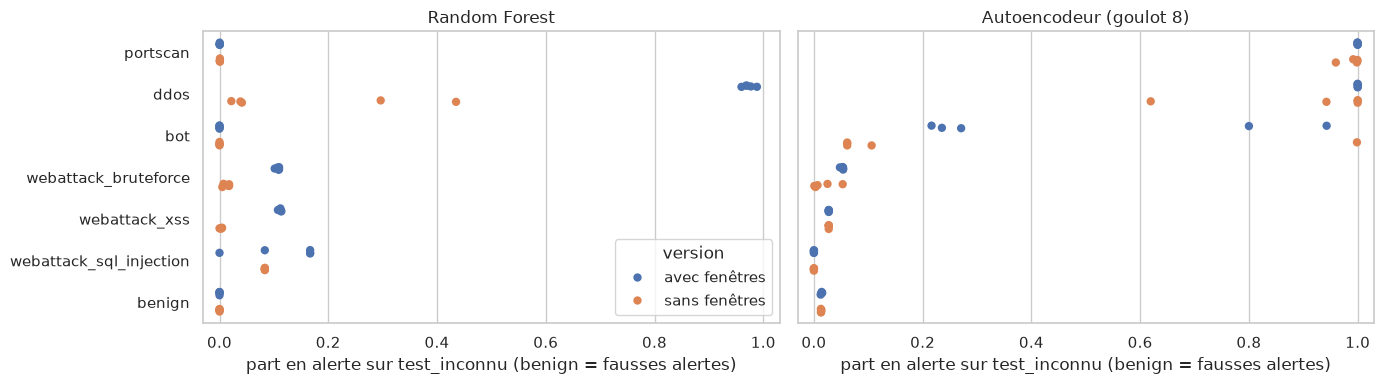

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, name, runs in [(axes[0], "Random Forest", rf_runs), (axes[1], "Autoencodeur (goulot 8)", ae_runs)]:
    long_rows = []
    for _, row in runs.iterrows():
        for cls in classes:
            long_rows.append({"classe": cls, "version": row["version"], "part": row[cls]})
    sns.stripplot(data=pd.DataFrame(long_rows), y="classe", x="part", hue="version", dodge=True, size=6,
                  palette={"avec fenêtres": "#4C72B0", "sans fenêtres": "#DD8452"}, ax=ax)
    ax.set_xlim(-0.03, 1.03)
    ax.set_title(name)
    ax.set_xlabel("part en alerte sur test_inconnu (benign = fausses alertes)")
    ax.set_ylabel("")
axes[1].get_legend().remove()
fig.tight_layout()
fig.savefig(REPORTS / "04c_fenetres_rf_ae.png", dpi=150)
plt.show()

## Observations

1. **L'autoencodeur ne dépend presque pas des fenêtres pour le portscan.** Détection de 100 % avec fenêtres, et de 99,0 % [96,0 ; 100] sans elles. Le portscan reste donc bien visible grâce aux colonnes du flux lui-même.
2. **Il en dépend peu pour la DDoS, avec une exception.** De 100 % à 91,2 % en moyenne : 4 graines sur 5 restent à 94 % ou plus, et une descend à 61,9 %.
3. **Le RF dépend fortement des fenêtres pour la DDoS.** De 97,3 % [96,0 ; 98,8] à 16,7 % [2,2 ; 43,5]. Sans le volume par minute, la DDoS ne ressemble plus assez à dos_hulk.
4. **Les attaques web restent mal vues, et encore moins sans fenêtres :** RF de 10,7 et 11,2 % à 1,3 et 0,3 % (bruteforce, XSS).
5. **Bot est instable avec ou sans fenêtres :** 49,3 % [21,6 ; 94,3] avec, 25,8 % [6,1 ; 99,9] sans. Avec la même graine 0, on obtient 73,5 % dans les notebooks 04 et 04b, et 80,0 % ici, pour un rappel sur val presque identique (0,8739 et 0,8737). Le modèle enregistré, lui, redonne bien 73,5 %.
6. **Sur val, les attaques connues profitent des fenêtres.** Le rappel moyen de l'autoencodeur passe de 0,869 à 0,544. Le macro-F1 du RF, sans heartbleed, passe de 0,972 à 0,963.
7. **Conséquence pour le pipeline.** Les principales détections inconnues de l'autoencodeur (portscan, DDoS) ne reposent pas surtout sur le profil de scénario trouvé dans le notebook 04b. L'étiquette « dos_hulk » que le RF donne à la DDoS en dépend, elle, fortement.
8. **Limite.** Ces tests ne montrent pas ce que feraient les modèles sur un autre réseau : les autres colonnes peuvent aussi contenir des propriétés propres à LYCOS.